# Import Libraries

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import sklearn.metrics as metrics
from sklearn.preprocessing import StandardScaler
from scipy.stats import skew, kurtosis


warnings.filterwarnings("ignore", category=FutureWarning)

# Display and plotting settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)

# A fixed seed makes the train/test split, and so every result below, reproducible
RANDOM_STATE = 42

# Import Data

In [2]:
DATA_PATH = r"C:\Users\bilal\Desktop\gitRepo\Locked\LockedItems\Datasets\Span_new.csv"

df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Dataset loaded: 92,385 rows x 11 columns


,Unnamed: 0,ID,make,model,months_old,power,gear,fuel_type,kms,price,age
0,0,97860,Porsche,911,240,210,manual,gasoline,202000,999999,1998
1,1,27821,Ford,Mustang,54,487,manual,gasoline,30000,685000,2013
2,2,97801,Porsche,911,358,220,manual,gasoline,56300,555555,1988
3,3,98251,Porsche,911,14,368,manual,gasoline,2800,470000,2016
4,4,98250,Porsche,911,3,515,unknown,gasoline,10,450000,2017


# EDA 

In [3]:
print(df.shape)
df.info()
df.head()

(92385, 11)
<class 'pandas.DataFrame'>
RangeIndex: 92385 entries, 0 to 92384
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  92385 non-null  int64
 1   ID          92385 non-null  int64
 2   make        92385 non-null  str  
 3   model       92385 non-null  str  
 4   months_old  92385 non-null  int64
 5   power       92385 non-null  int64
 6   gear        92385 non-null  str  
 7   fuel_type   92385 non-null  str  
 8   kms         92385 non-null  int64
 9   price       92385 non-null  int64
 10  age         92385 non-null  int64
dtypes: int64(7), str(4)
memory usage: 9.9 MB


,Unnamed: 0,ID,make,model,months_old,power,gear,fuel_type,kms,price,age
0,0,97860,Porsche,911,240,210,manual,gasoline,202000,999999,1998
1,1,27821,Ford,Mustang,54,487,manual,gasoline,30000,685000,2013
2,2,97801,Porsche,911,358,220,manual,gasoline,56300,555555,1988
3,3,98251,Porsche,911,14,368,manual,gasoline,2800,470000,2016
4,4,98250,Porsche,911,3,515,unknown,gasoline,10,450000,2017


In [4]:
df.columns

Index(['Unnamed: 0', 'ID', 'make', 'model', 'months_old', 'power', 'gear',
       'fuel_type', 'kms', 'price', 'age'],
      dtype='str')

### Drop the Unnamed - Leftovers

In [5]:
df.drop(columns="Unnamed: 0")

,ID,make,model,months_old,power,gear,fuel_type,kms,price,age
0,97860,Porsche,911,240,210,manual,gasoline,202000,999999,1998
1,27821,Ford,Mustang,54,487,manual,gasoline,30000,685000,2013
2,97801,Porsche,911,358,220,manual,gasoline,56300,555555,1988
3,98251,Porsche,911,14,368,manual,gasoline,2800,470000,2016
4,98250,Porsche,911,3,515,unknown,gasoline,10,450000,2017
...,...,...,...,...,...,...,...,...,...,...
92380,38173,Opel,Astra,275,52,manual,gasoline,134700,350,1995
92381,57303,Volkswagen,Polo,232,37,manual,gasoline,67762,350,1998
92382,14541,Bmw,320,186,125,manual,gasoline,200000,300,2002
92383,103604,Seat,Toledo,276,66,manual,gasoline,196000,300,1995


In [6]:
numeric_cols = ["price", "power", "kms", "months_old", "age"]
catagorical_cols = ["make", "model", "gear", "fuel_type"]

### Check skewness and kurtosis for every column

In [7]:
# Drop null

In [8]:
df.dropna()

,Unnamed: 0,ID,make,model,months_old,power,gear,fuel_type,kms,price,age
0,0,97860,Porsche,911,240,210,manual,gasoline,202000,999999,1998
1,1,27821,Ford,Mustang,54,487,manual,gasoline,30000,685000,2013
2,2,97801,Porsche,911,358,220,manual,gasoline,56300,555555,1988
3,3,98251,Porsche,911,14,368,manual,gasoline,2800,470000,2016
4,4,98250,Porsche,911,3,515,unknown,gasoline,10,450000,2017
...,...,...,...,...,...,...,...,...,...,...,...
92380,93986,38173,Opel,Astra,275,52,manual,gasoline,134700,350,1995
92381,93987,57303,Volkswagen,Polo,232,37,manual,gasoline,67762,350,1998
92382,93988,14541,Bmw,320,186,125,manual,gasoline,200000,300,2002
92383,93989,103604,Seat,Toledo,276,66,manual,gasoline,196000,300,1995


In [78]:
shape_tbl = pd.DataFrame({
    'Skew': df[numeric_cols].skew(),
    'Kurtosis': df[numeric_cols].kurtosis()
}).sort_values(by='Skew', ascending=False)

display(shape_tbl)

,Skew,Kurtosis
price,9.09,286.61
power,2.74,13.78
months_old,1.22,1.40
kms,1.07,1.02
age,-1.22,1.39


### Drop duplicates

In [10]:
df.duplicated().sum()

np.int64(0)

### Test by visuals

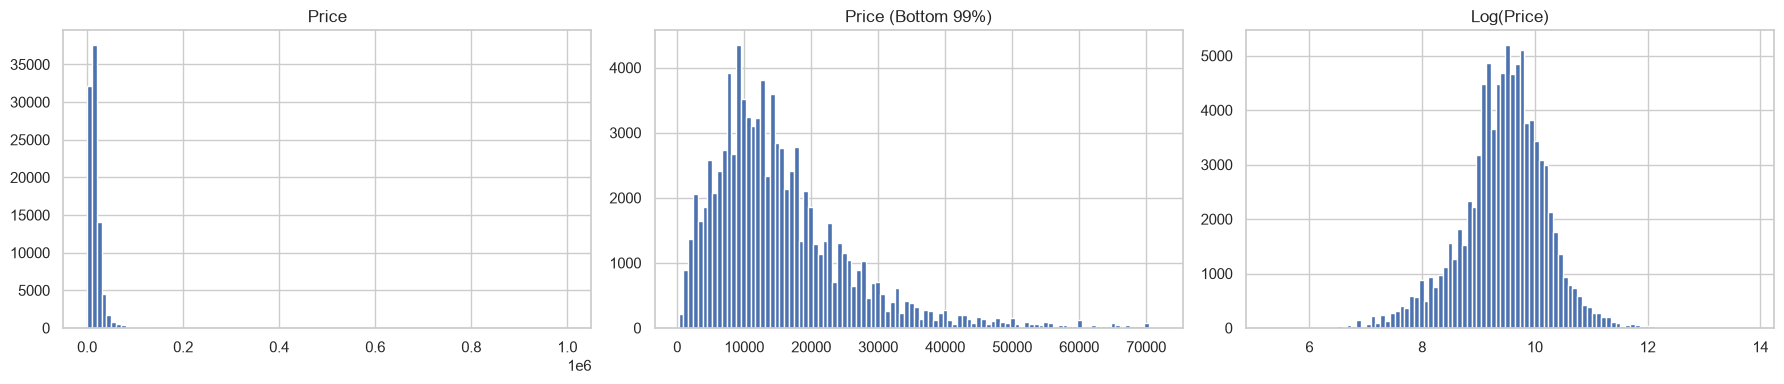

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))

ax[0].hist(df.price, bins=100)
ax[0].set_title('Price')

ax[1].hist(df.price[df.price < df.price.quantile(0.99)], bins=100)
ax[1].set_title('Price (Bottom 99%)')

ax[2].hist(np.log(df.price[df.price > 0]), bins=100)
ax[2].set_title('Log(Price)')

plt.tight_layout()
plt.show()

### Check values in columns by abundance

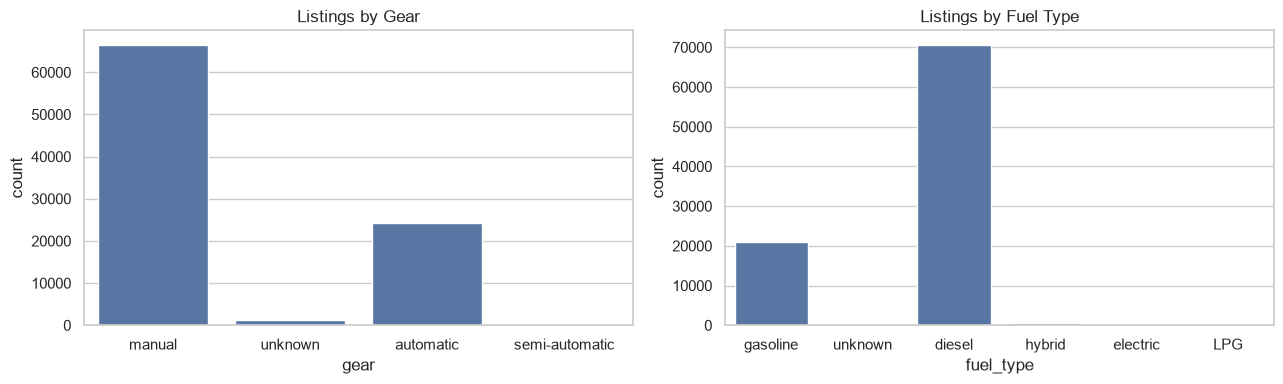

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(data=df, x='gear', ax=axes[0])
sns.countplot(data=df, x='fuel_type', ax=axes[1])

axes[0].set_title('Listings by Gear')
axes[1].set_title('Listings by Fuel Type')

plt.tight_layout()
plt.show()

### Distribution of target variables

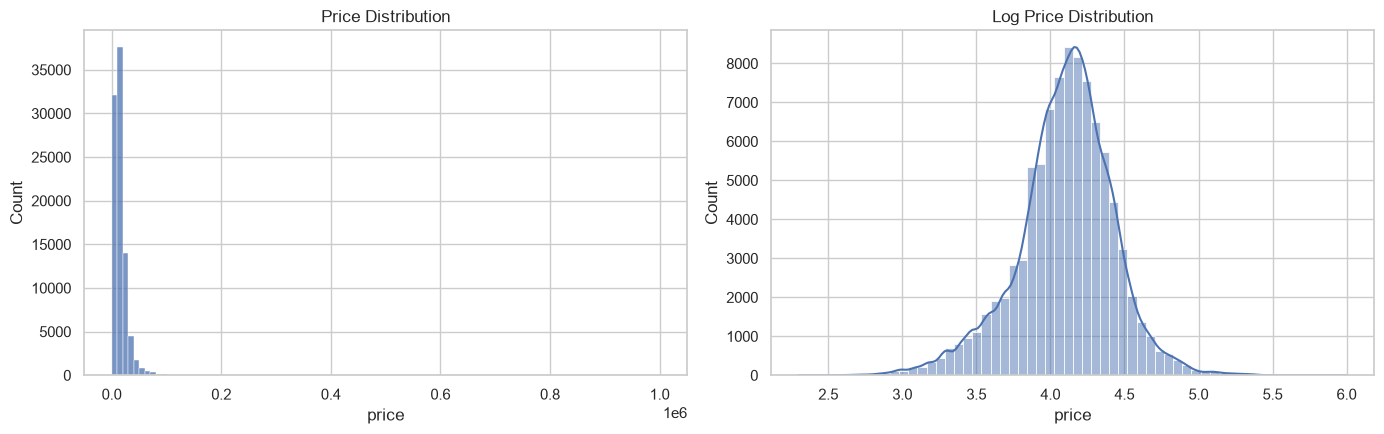

Skewness: 9.09


In [80]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(df.price, bins=100, ax=axes[0])
axes[0].set_title('Price Distribution')
axes[1].set_title('Log Price Distribution')

sns.histplot(np.log10(df.price), bins=60, kde=True, ax=axes[1])

plt.tight_layout()
plt.show()

print('Skewness:', round(df.price.skew(), 2))

### Correlation check

<Axes: >

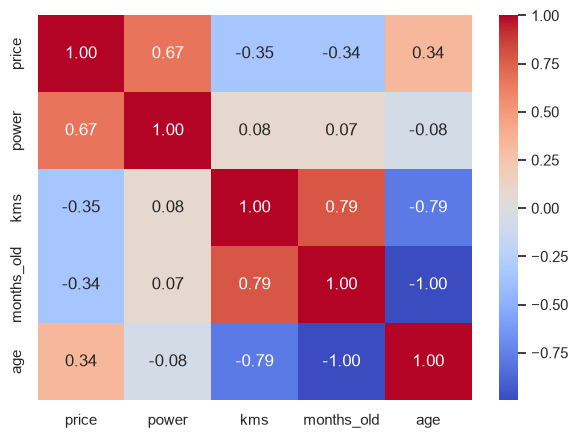

In [83]:
plt.figure(figsize=(7, 5))
# sns.heatmap(df[['price', 'power', 'age', 'months_old', 'kms']].corr(),
#             annot=True, cmap='coolwarm', fmt='.2f')
# plt.title('Correlation Matrix')


sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')

### Numeric variables Distribution

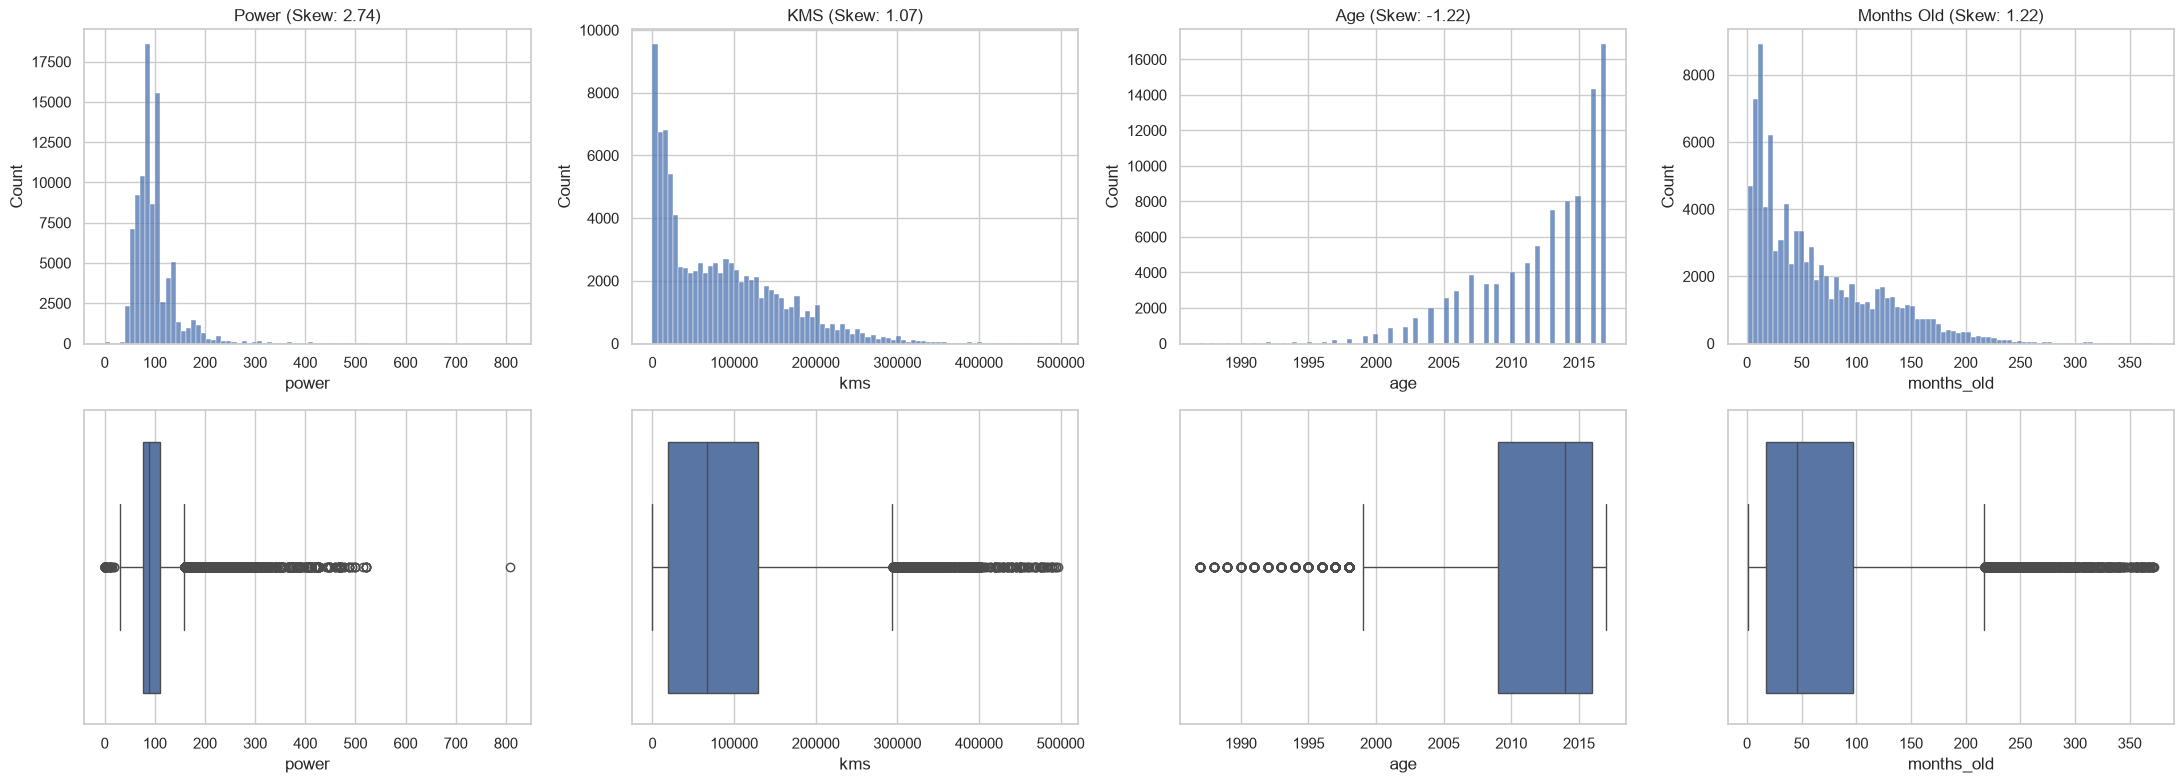

In [84]:
fig, ax = plt.subplots(2, 4, figsize=(22, 8))

sns.histplot(df['power'], bins=80, ax=ax[0, 0])
sns.histplot(df['kms'], bins=80, ax=ax[0, 1])
sns.histplot(df['age'], bins=80, ax=ax[0, 2])
sns.histplot(df['months_old'], bins=80, ax=ax[0, 3])

sns.boxplot(x=df['power'], ax=ax[1, 0])
sns.boxplot(x=df['kms'], ax=ax[1, 1])
sns.boxplot(x=df['age'], ax=ax[1, 2])
sns.boxplot(x=df['months_old'], ax=ax[1, 3])

ax[0, 0].set_title(f"Power (Skew: {df['power'].skew():.2f})")
ax[0, 1].set_title(f"KMS (Skew: {df['kms'].skew():.2f})")
ax[0, 2].set_title(f"Age (Skew: {df['age'].skew():.2f})")
ax[0, 3].set_title(f"Months Old (Skew: {df['months_old'].skew():.2f})")

plt.tight_layout()
plt.show()

### Numeric features vs price

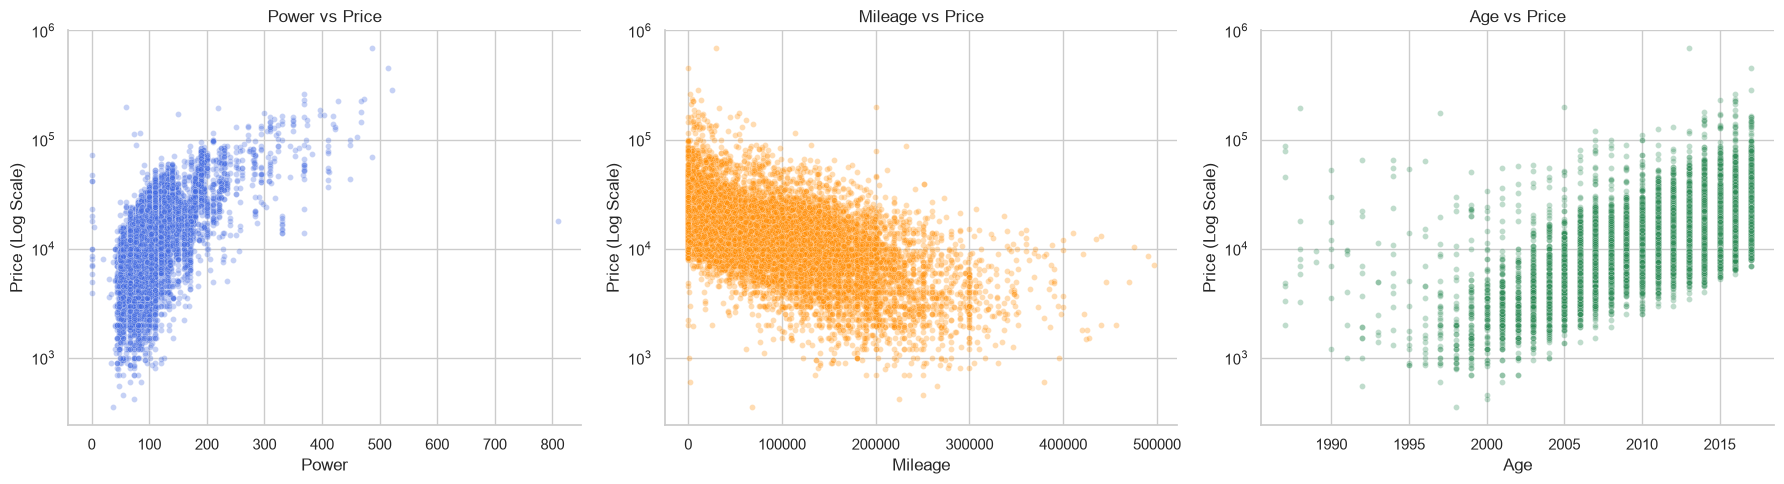

In [85]:
s = df.sample(min(15000, len(df)), random_state=1)

sns.set_theme(style='whitegrid', context='notebook')

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=s, x='power', y='price', alpha=0.3, s=18, color='royalblue', ax=ax[0])
sns.scatterplot(data=s, x='kms', y='price', alpha=0.3, s=18, color='darkorange', ax=ax[1])
sns.scatterplot(data=s, x='age', y='price', alpha=0.3, s=18, color='seagreen', ax=ax[2])

ax[0].set_title('Power vs Price')
ax[1].set_title('Mileage vs Price')
ax[2].set_title('Age vs Price')

for a in ax:
    a.set_yscale('log')
    a.set_ylabel('Price (Log Scale)')
    a.set_xlabel(a.get_title().split(' vs ')[0])

sns.despine()
plt.tight_layout()
plt.show()

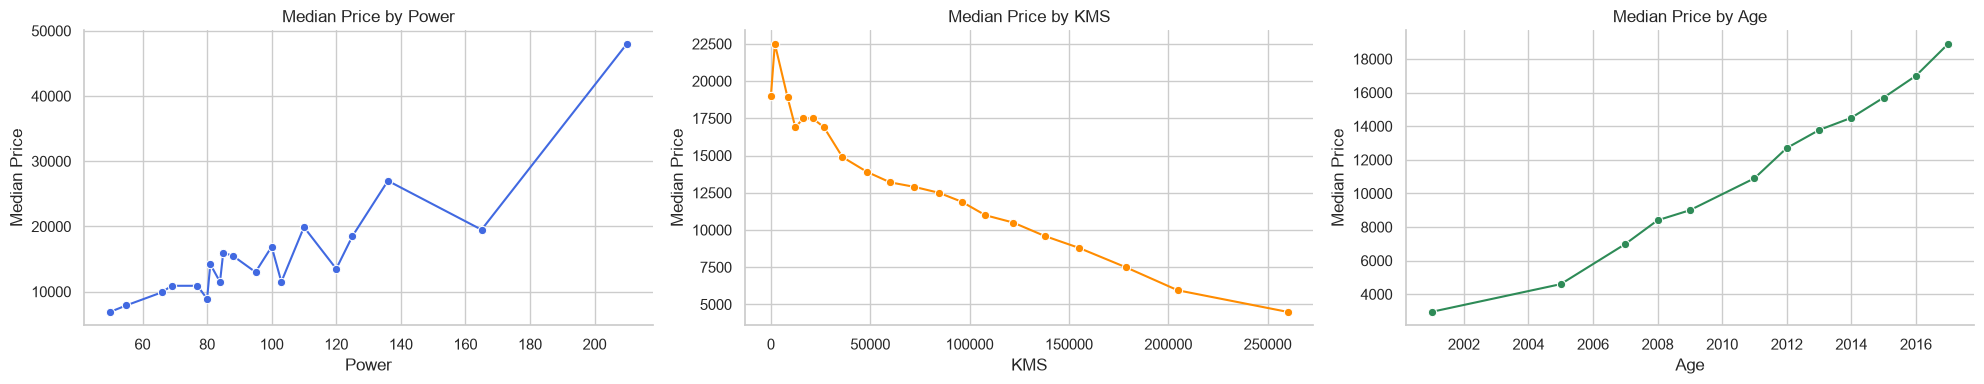

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(20, 4))

# Power
bins = pd.qcut(df['power'], 20, duplicates='drop')
g = df.groupby(bins, observed=True).agg(x=('power', 'median'), price=('price', 'median'))
sns.lineplot(data=g, x='x', y='price', marker='o', color='royalblue', ax=ax[0])
ax[0].set_title('Median Price by Power')
ax[0].set_xlabel('Power')
ax[0].set_ylabel('Median Price')

# KMS
bins = pd.qcut(df['kms'], 20, duplicates='drop')
g = df.groupby(bins, observed=True).agg(x=('kms', 'median'), price=('price', 'median'))
sns.lineplot(data=g, x='x', y='price', marker='o', color='darkorange', ax=ax[1])
ax[1].set_title('Median Price by KMS')
ax[1].set_xlabel('KMS')
ax[1].set_ylabel('Median Price')

# Age
bins = pd.qcut(df['age'], 20, duplicates='drop')
g = df.groupby(bins, observed=True).agg(x=('age', 'median'), price=('price', 'median'))
sns.lineplot(data=g, x='x', y='price', marker='o', color='seagreen', ax=ax[2])
ax[2].set_title('Median Price by Age')
ax[2].set_xlabel('Age')
ax[2].set_ylabel('Median Price')

sns.despine()
plt.tight_layout()
plt.show()

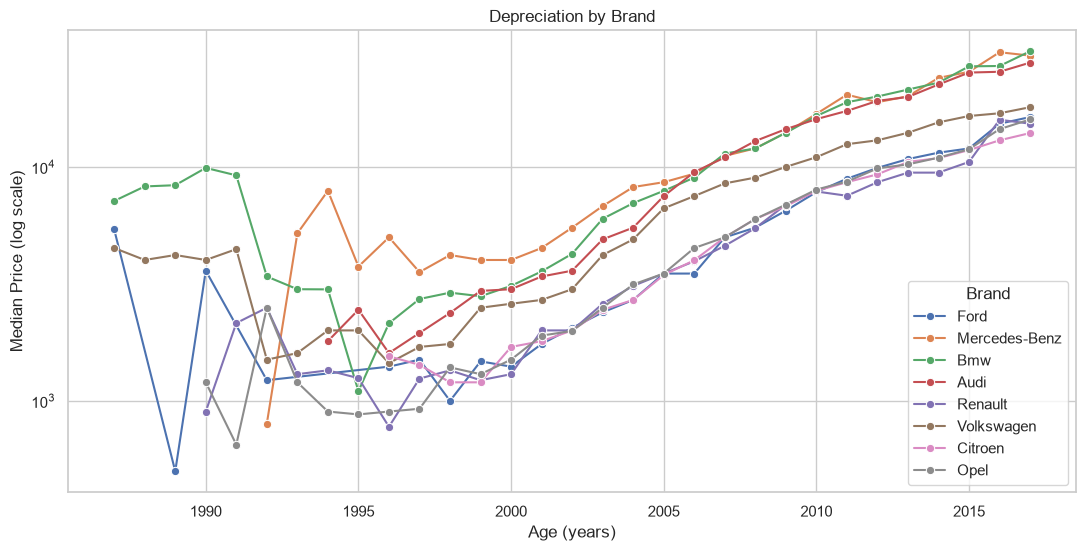

In [18]:
top_makes = df['make'].value_counts().head(8).index

sns.set_theme(style='whitegrid')

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=df[df['make'].isin(top_makes)],
    x=df['age'].round(),
    y='price',
    hue='make',
    estimator='median',
    errorbar=None,
    marker='o'
)

plt.yscale('log')
plt.xlabel('Age (years)')
plt.ylabel('Median Price (log scale)')
plt.title('Depreciation by Brand')
plt.legend(title='Brand')
plt.show()

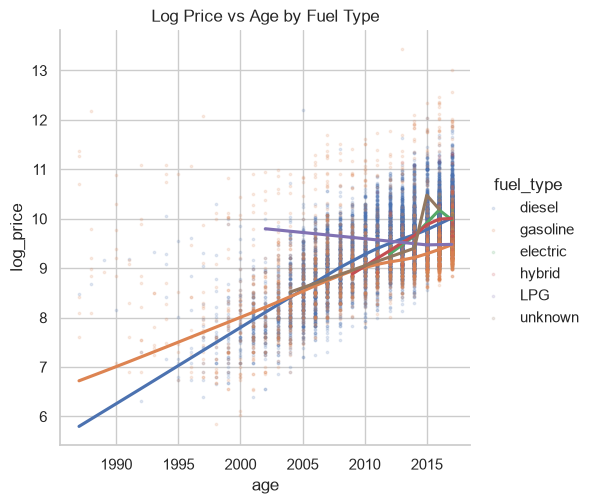

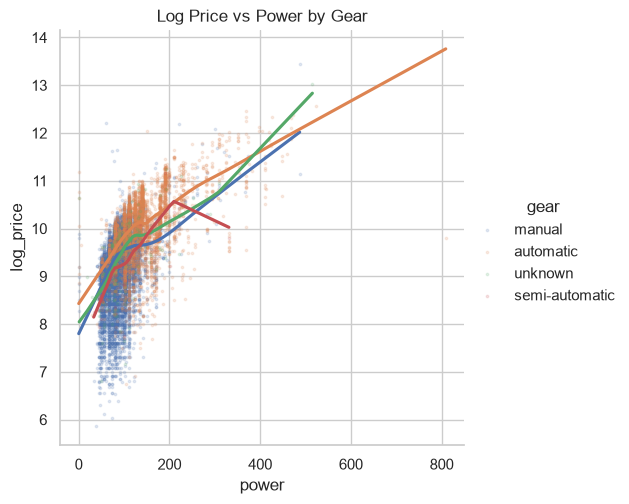

In [19]:
s = df.sample(min(15000, len(df)), random_state=1).copy()
s['log_price'] = np.log(s.price.clip(lower=1))

sns.lmplot(data=s, x='age', y='log_price', hue='fuel_type',
           lowess=True, scatter_kws={'s': 3, 'alpha': 0.15})
plt.title('Log Price vs Age by Fuel Type')
plt.show()

sns.lmplot(data=s, x='power', y='log_price', hue='gear',
           lowess=True, scatter_kws={'s': 3, 'alpha': 0.15})
plt.title('Log Price vs Power by Gear')
plt.show()

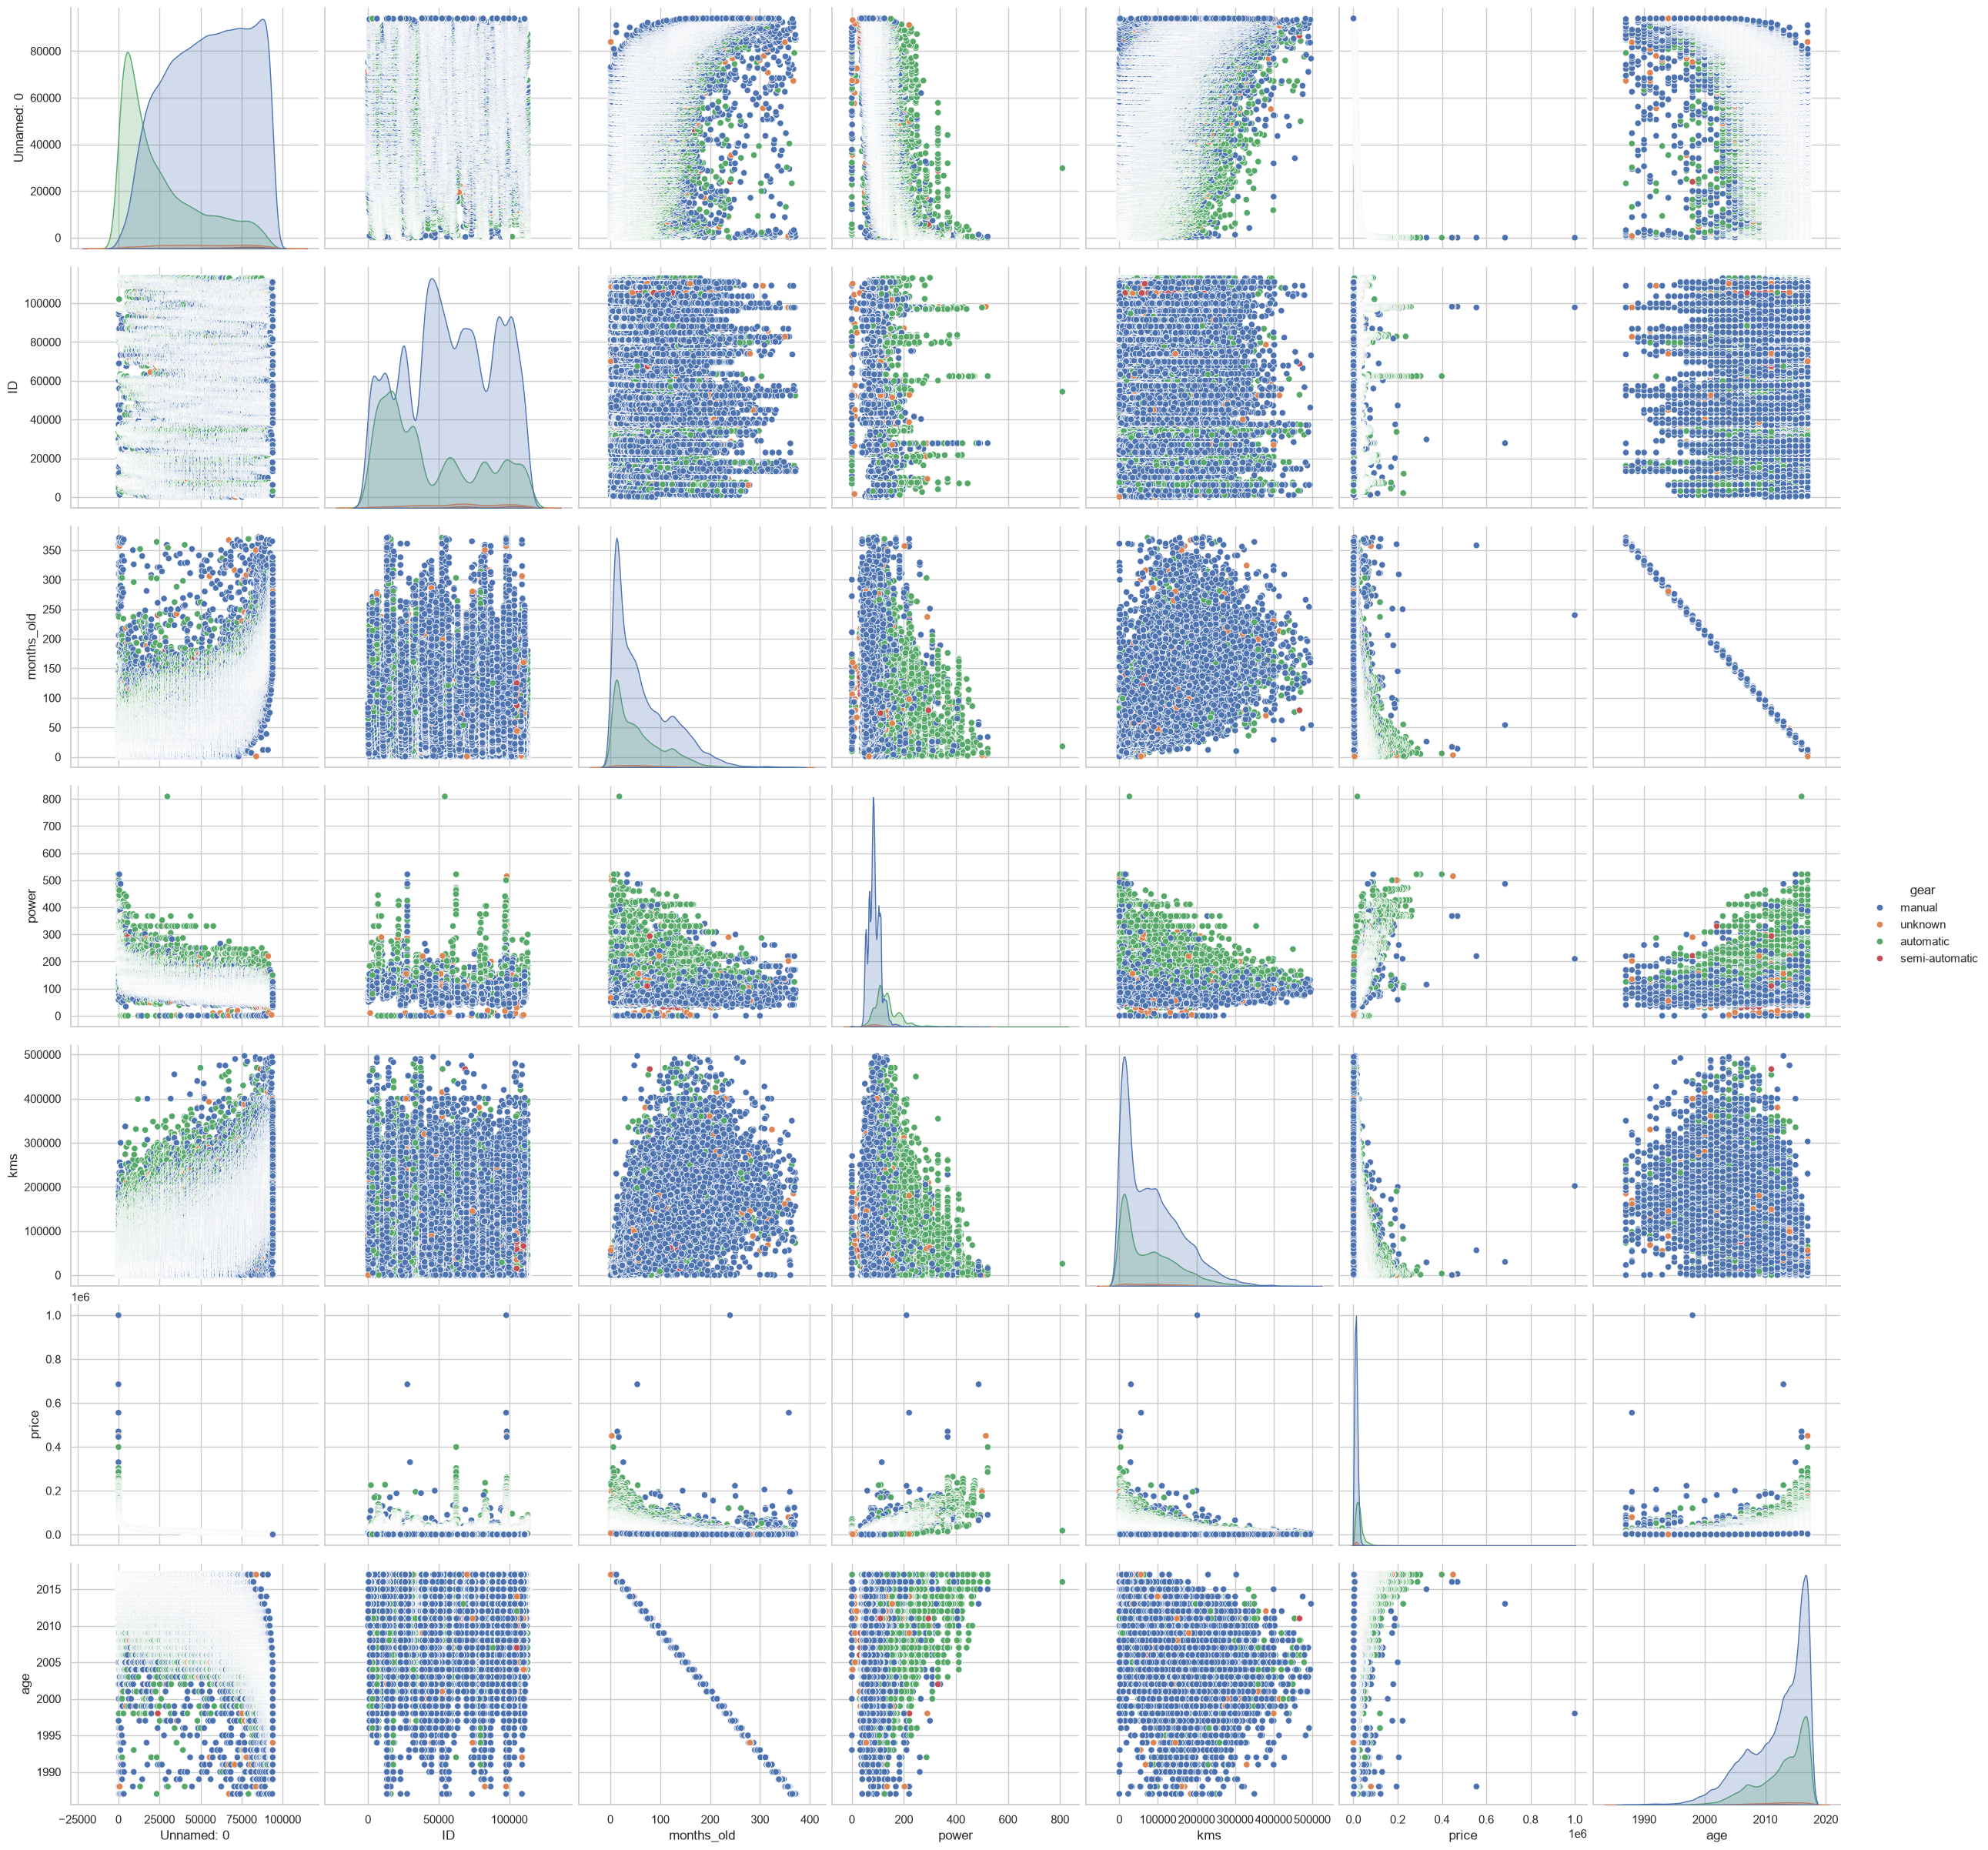

In [20]:
sns.pairplot(df, hue='gear', height=3.5)

<Axes: xlabel='fuel_type', ylabel='price'>

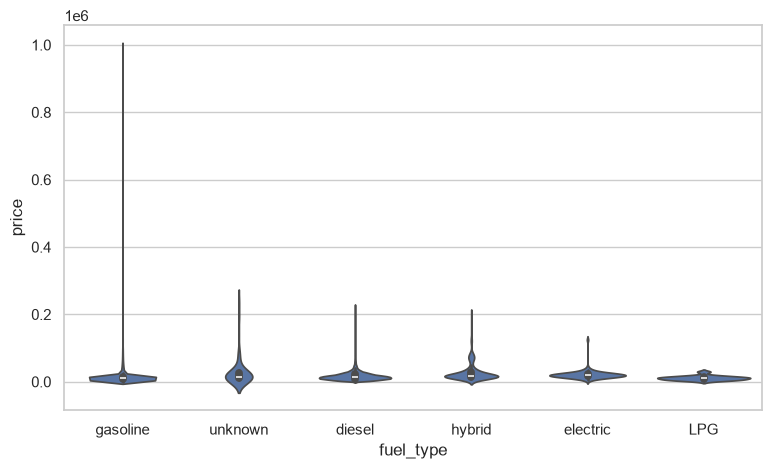

In [21]:
sns.violinplot(data=df, x='fuel_type', y='price')

In [22]:
print(df[["months_old", "age"]].corr())
df[["months_old", "age"]].head(10)

            months_old   age
months_old        1.00 -1.00
age              -1.00  1.00


,months_old,age
0,240,1998
1,54,2013
2,358,1988
3,14,2016
4,3,2017
5,17,2016
6,6,2017
7,26,2015
8,5,2017
9,14,2016


In [23]:
# both of above hold the same information

In [24]:
print(df["model"].nunique())
df["model"].value_counts().head(20)

247


model
Golf        2433
A4          2085
A3          2039
Leon        1841
Astra       1696
Focus       1679
320         1672
Ibiza       1652
Megane      1633
Corsa       1336
Clio        1242
Polo        1205
308         1190
Qashqai     1101
Fiesta      1078
C220        1046
318         1044
Insignia    1033
116         1005
A6           964
Name: count, dtype: int64

In [25]:
# Missing Values and Unknowns

In [26]:
df.isna().sum()

Unnamed: 0    0
ID            0
make          0
model         0
months_old    0
power         0
gear          0
fuel_type     0
kms           0
price         0
age           0
dtype: int64

In [27]:
df.gear.value_counts()

gear
manual            66584
automatic         24275
unknown            1234
semi-automatic      292
Name: count, dtype: int64

In [28]:
# I will keep the gear as there are huge amount of values

### Check for duplicates

In [29]:
df.duplicated().sum()

np.int64(0)

### Impossible or suspicious values

In [30]:
checks = {
    "price <= 0":                 (df.price <= 0).sum(),
    "price < 500":                (df.price < 500).sum(),
    "price > 500,000":            (df.price > 500_000).sum(),
    "power <= 0":                 (df.power <= 0).sum(),
    "power > 800":                (df.power > 800).sum(),
    "kms < 0":                    (df.kms < 0).sum(),
    "kms > 1,000,000":            (df.kms > 1_000_000).sum(),
    "months_old < 0":             (df.months_old < 0).sum(),
    "age < 0":                    (df.age < 0).sum(),
    "age > 50":                   (df.age > 50).sum(),
    "0 kms but older than 1 yr":  ((df.kms == 0) & (df.age > 1)).sum(),
}
display(pd.Series(checks, name="rows"))

price <= 0                       0
price < 500                     17
price > 500,000                  3
power <= 0                      61
power > 800                      1
kms < 0                          0
kms > 1,000,000                  0
months_old < 0                   0
age < 0                          0
age > 50                     92385
0 kms but older than 1 yr        0
Name: rows, dtype: int64

# Start filtering Data

In [31]:
filtered_cars_data = df[(df.gear == 'manual') | (df.gear == 'automatic')]
filtered_cars_data.gear.value_counts()

gear
manual       66584
automatic    24275
Name: count, dtype: int64

### Variables under consideration

In [32]:
independent_vaiable = filtered_cars_data[['months_old','power', 'kms']]
dependent_vaiable = filtered_cars_data[['price']]

In [33]:
x_train, x_test, y_train, y_test = train_test_split(independent_vaiable, dependent_vaiable, test_size= 0.2)
x_train.describe()

,months_old,power,kms
count,"72,687.00","72,687.00","72,687.00"
mean,63.50,99.90,"82,752.08"
std,56.84,42.75,"75,028.61"
min,1.00,0.00,1.00
25%,16.00,77.00,"18,394.00"
50%,46.00,88.00,"66,000.00"
75%,97.00,110.00,"129,000.00"
max,372.00,522.00,"497,000.00"


In [34]:
# Regresssion model
regression_model = sm.OLS(y_train, x_train)
results = regression_model.fit()

results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                  price   R-squared (uncentered):                   0.827
Model:                            OLS   Adj. R-squared (uncentered):              0.827
Method:                 Least Squares   F-statistic:                          1.155e+05
Date:                Sat, 21 Nov 2026   Prob (F-statistic):                        0.00
Time:                        02:25:20   Log-Likelihood:                     -7.6848e+05
No. Observations:               72687   AIC:                                  1.537e+06
Df Residuals:                   72684   BIC:                                  1.537e+06
Df Model:                           3                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
months_old   -59.3372      0.992    -59.810      0.000     -61.282     -57.393
power        246.8330      0.465    530.988      0.000     245.922     247.744
kms           -0.0503      0.001    -66.615      0.000      -0.052      -0.049
==============================================================================
Omnibus:                   170147.927   Durbin-Watson:                   2.001
Prob(Omnibus):                  0.000   Jarque-Bera (JB):       9839573186.139
Skew:                          22.537   Prob(JB):                         0.00
Kurtosis:                    1804.895   Cond. No.                     3.18e+03
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[3] The condition number is large, 3.18e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [35]:
predictions = results.predict(x_test)

In [36]:
mar = metrics.mean_absolute_error(y_test, predictions)
mse = metrics.mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = metrics.r2_score(y_test, predictions)

print("mar = ", mar)
print("mse = ", mse)
print("rmse = ", rmse)
print("r2 = ", r2)

mar =  4748.81565540842
mse =  98617744.9847104
rmse =  9930.64675561015
r2 =  0.6002639413449502


### Standardization of data (Z score)

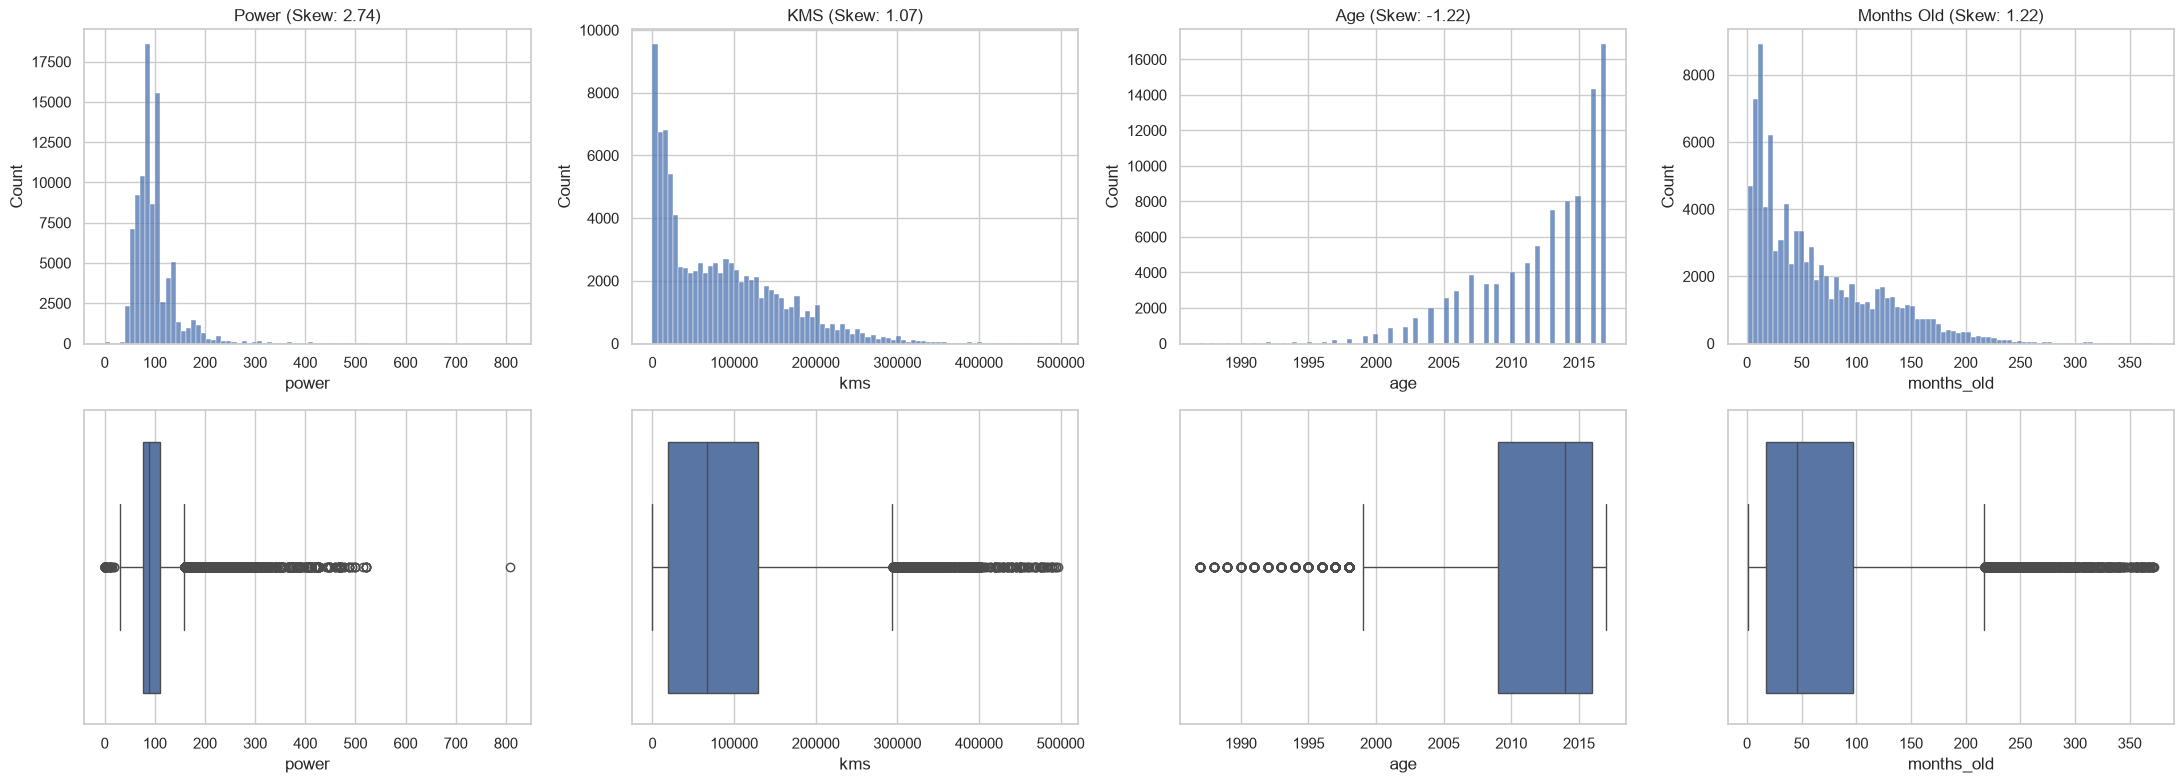

In [37]:
fig, ax = plt.subplots(2, 4, figsize=(22, 8))

sns.histplot(df['power'], bins=80, ax=ax[0, 0])
sns.histplot(df['kms'], bins=80, ax=ax[0, 1])
sns.histplot(df['age'], bins=80, ax=ax[0, 2])
sns.histplot(df['months_old'], bins=80, ax=ax[0, 3])

sns.boxplot(x=df['power'], ax=ax[1, 0])
sns.boxplot(x=df['kms'], ax=ax[1, 1])
sns.boxplot(x=df['age'], ax=ax[1, 2])
sns.boxplot(x=df['months_old'], ax=ax[1, 3])

ax[0, 0].set_title(f"Power (Skew: {df['power'].skew():.2f})")
ax[0, 1].set_title(f"KMS (Skew: {df['kms'].skew():.2f})")
ax[0, 2].set_title(f"Age (Skew: {df['age'].skew():.2f})")
ax[0, 3].set_title(f"Months Old (Skew: {df['months_old'].skew():.2f})")

plt.tight_layout()

In [38]:
standard_scalar = StandardScaler()

In [39]:
variables_in_study = filtered_cars_data[['months_old','power','kms','price']]

In [40]:
standard_scalar.fit(variables_in_study)
variables_in_study = standard_scalar.transform(variables_in_study)

In [41]:
#Numeric data distribution after transformation

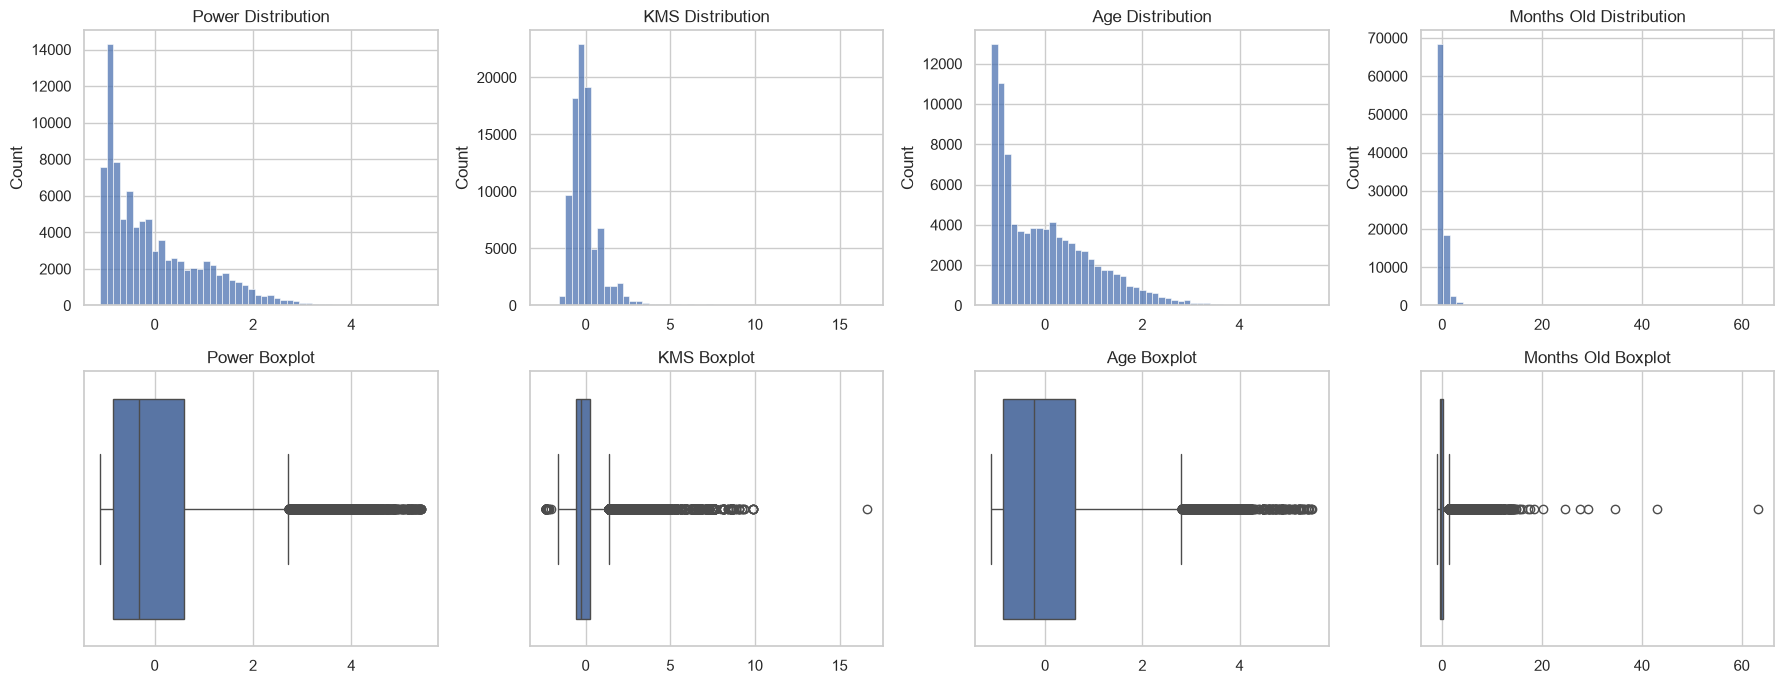

In [42]:
fig, ax = plt.subplots(2, 4, figsize=(18, 7))

sns.histplot(variables_in_study[:, 0], bins=50, ax=ax[0, 0])
sns.histplot(variables_in_study[:, 1], bins=50, ax=ax[0, 1])
sns.histplot(variables_in_study[:, 2], bins=50, ax=ax[0, 2])
sns.histplot(variables_in_study[:, 3], bins=50, ax=ax[0, 3])

sns.boxplot(x=variables_in_study[:, 0], ax=ax[1, 0])
sns.boxplot(x=variables_in_study[:, 1], ax=ax[1, 1])
sns.boxplot(x=variables_in_study[:, 2], ax=ax[1, 2])
sns.boxplot(x=variables_in_study[:, 3], ax=ax[1, 3])

ax[0, 0].set_title('Power Distribution')
ax[0, 1].set_title('KMS Distribution')
ax[0, 2].set_title('Age Distribution')
ax[0, 3].set_title('Months Old Distribution')

ax[1, 0].set_title('Power Boxplot')
ax[1, 1].set_title('KMS Boxplot')
ax[1, 2].set_title('Age Boxplot')
ax[1, 3].set_title('Months Old Boxplot')

plt.tight_layout()

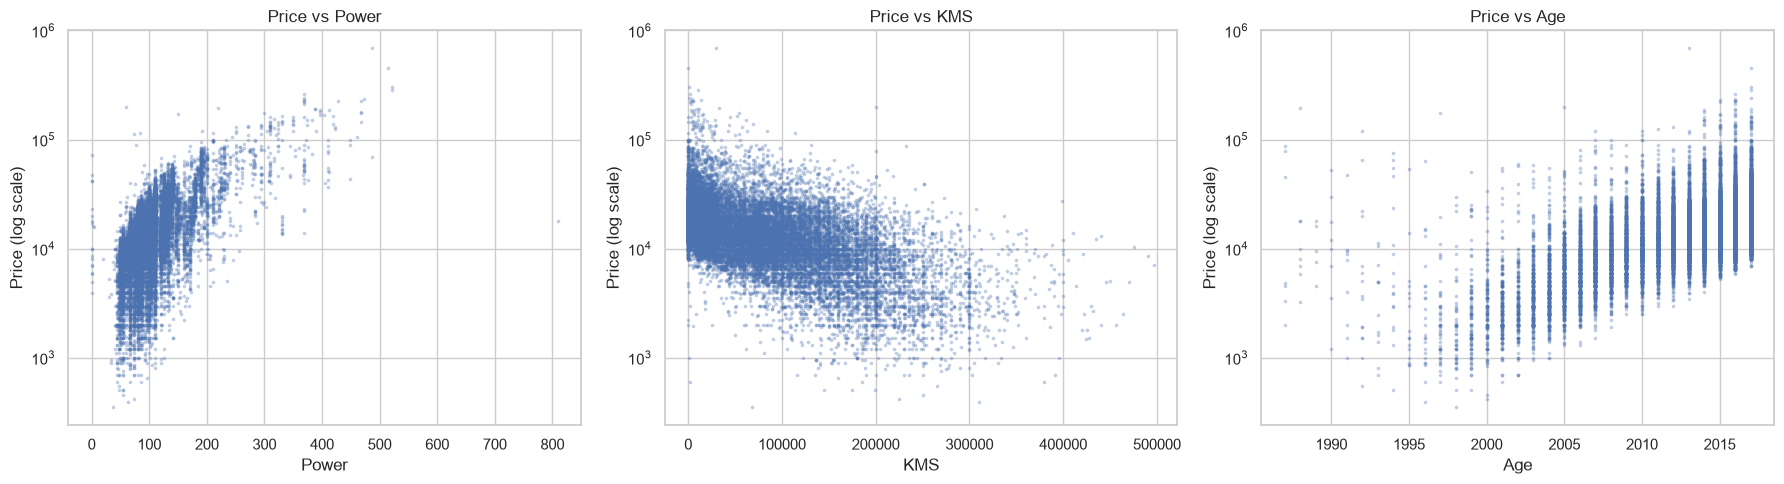

In [43]:
s = df.sample(n=min(20000, len(df)), random_state=1)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

ax[0].scatter(s["power"], s["price"], s=3, alpha=0.25)
ax[0].set_yscale("log")
ax[0].set_title("Price vs Power")
ax[0].set_xlabel("Power")
ax[0].set_ylabel("Price (log scale)")

ax[1].scatter(s["kms"], s["price"], s=3, alpha=0.25)
ax[1].set_yscale("log")
ax[1].set_title("Price vs KMS")
ax[1].set_xlabel("KMS")
ax[1].set_ylabel("Price (log scale)")

ax[2].scatter(s["age"], s["price"], s=3, alpha=0.25)
ax[2].set_yscale("log")
ax[2].set_title("Price vs Age")
ax[2].set_xlabel("Age")
ax[2].set_ylabel("Price (log scale)")

plt.tight_layout()
plt.show()

In [44]:
car_data = pd.DataFrame(variables_in_study, columns=['months_old','power','kms','price'])
car_data.head()

,months_old,power,kms,price
0,3.10,2.58,1.58,63.27
1,-0.17,9.07,-0.70,43.00
2,5.18,2.82,-0.35,34.68
3,-0.87,6.28,-1.06,29.17
4,-0.82,6.28,-1.10,27.56


### Numeric data distribution after transformation

In [45]:
independent_vaiable = car_data[['months_old','power', 'kms']]
dependent_vaiable = car_data[['price']]

independent_vaiable = sm.add_constant(independent_vaiable)


In [46]:
x_train, x_test, y_train, y_test = train_test_split(independent_vaiable, dependent_vaiable, test_size= 0.2)

In [47]:
regression_model = sm.OLS(y_train, x_train)
results = regression_model.fit()

results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.626
Model:                            OLS   Adj. R-squared:                  0.626
Method:                 Least Squares   F-statistic:                 4.047e+04
Date:                Sat, 21 Nov 2026   Prob (F-statistic):               0.00
Time:                        02:25:24   Log-Likelihood:                -67547.
No. Observations:               72687   AIC:                         1.351e+05
Df Residuals:                   72683   BIC:                         1.351e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0010      0.002      0.433      0.665      -0.003       0.005
months_old    -0.2106      0.004    -57.157      0.000      -0.218      -0.203
power          0.7054      0.002    308.379      0.000       0.701       0.710
kms           -0.2378      0.004    -64.458      0.000      -0.245      -0.231
==============================================================================
Omnibus:                   169217.820   Durbin-Watson:                   2.003
Prob(Omnibus):                  0.000   Jarque-Bera (JB):       9279485303.007
Skew:                          22.242   Prob(JB):                         0.00
Kurtosis:                    1752.842   Cond. No.                         2.91
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [48]:
predictions = results.predict(x_test)

In [49]:
r2 = metrics.r2_score(y_test, predictions)


In [50]:
mar = metrics.mean_absolute_error(y_test, predictions)
mse = metrics.mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = metrics.r2_score(y_test, predictions)

print("mar = ", mar)
print("mse = ", mse)
print("rmse = ", rmse)
print("r2 = ", r2)

mar =  0.3063754851135108
mse =  0.3795683168956943
rmse =  0.6160911595662564
r2 =  0.6159834015860175


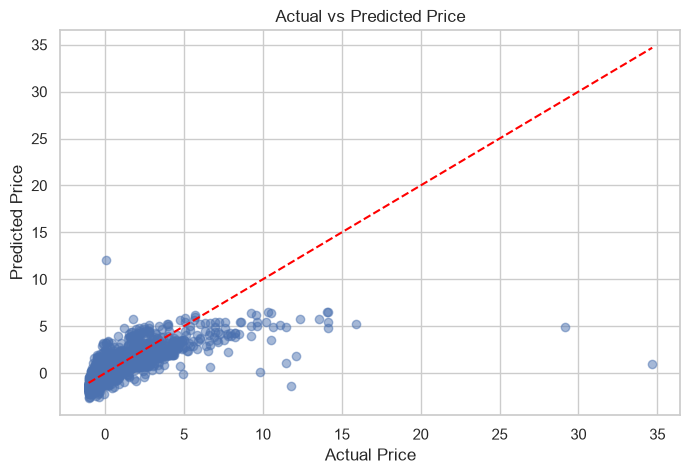

In [51]:
import seaborn as sns

plt.figure(figsize=(8,5))

plt.scatter(y_test, predictions, alpha=0.5)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)


# Predict new car

In [52]:
new_car = pd.DataFrame({
    'const': [1],
    'power': [1200],
    'age': [5000],
    'kms': [5000]
})

In [53]:
predicted_price = results.predict(new_car)

print('Predicted Car Price:', predicted_price.iloc[0])

Predicted Car Price: 2085.504426801881


# Implement all the ML Supervised learning algorithms

### Polynomial regression 

In [54]:
# Statistical Models
import statsmodels.api as sm

# Linear Regression
from sklearn.linear_model import LinearRegression

# Polynomial Regression
from sklearn.preprocessing import PolynomialFeatures

# Regularization Models
from sklearn.linear_model import Ridge, Lasso, ElasticNet

# Tree-Based Models
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Support Vector Regression
from sklearn.svm import SVR

# K-Nearest Neighbors
from sklearn.neighbors import KNeighborsRegressor

# Evaluation Metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Data Processing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Manipulation
import pandas as pd
import numpy as np

In [55]:
ols_model = sm.OLS(y_train, x_train)
ols_results = ols_model.fit()

ols_predictions = ols_results.predict(x_test)

In [56]:
lr_model = LinearRegression()
lr_model.fit(x_train, y_train)
lr_predictions = lr_model.predict(x_test)

In [57]:
poly = PolynomialFeatures(degree=2)

x_train_poly = poly.fit_transform(x_train)
x_test_poly = poly.transform(x_test)

poly_model = LinearRegression()
poly_model.fit(x_train_poly, y_train)

poly_predictions = poly_model.predict(x_test_poly)

In [58]:
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(x_train, y_train)
ridge_predictions = ridge_model.predict(x_test)

In [59]:
lasso_model = Lasso(alpha=1.0)
lasso_model.fit(x_train, y_train)
lasso_predictions = lasso_model.predict(x_test)

In [60]:
elastic_model = ElasticNet(alpha=1.0, l1_ratio=0.5)
elastic_model.fit(x_train, y_train)
elastic_predictions = elastic_model.predict(x_test)

In [61]:
dt_model = DecisionTreeRegressor(max_depth=5, random_state=1)
dt_model.fit(x_train, y_train)
dt_predictions = dt_model.predict(x_test)

In [62]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=1)
rf_model.fit(x_train, y_train)
rf_predictions = rf_model.predict(x_test)

C:\Users\bilal\anaconda3\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


In [63]:
gb_model = GradientBoostingRegressor(random_state=1)
gb_model.fit(x_train, y_train)
gb_predictions = gb_model.predict(x_test)

C:\Users\bilal\anaconda3\Lib\site-packages\sklearn\ensemble\_gb.py:691: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)  # TODO: Is this still required?


In [67]:
predictions = {
    "OLS": ols_predictions,
    "Linear Regression": lr_predictions,
    "Polynomial Regression": poly_predictions,
    "Ridge": ridge_predictions,
    "Lasso": lasso_predictions,
    "Elastic Net": elastic_predictions,
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions,
    "Gradient Boosting": gb_predictions
}

comparison = pd.DataFrame({
    name: {
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mean_squared_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2 Score": r2_score(y_test, pred)
    }
    for name, pred in predictions.items()
}).T

comparison.sort_values("R2 Score", ascending=False)

,MAE,MSE,RMSE,R2 Score
Gradient Boosting,0.21,0.22,0.47,0.78
Random Forest,0.18,0.26,0.51,0.74
Polynomial Regression,0.23,0.30,0.55,0.70
Decision Tree,0.25,0.31,0.56,0.68
Ridge,0.31,0.38,0.62,0.62
OLS,0.31,0.38,0.62,0.62
Linear Regression,0.31,0.38,0.62,0.62
Elastic Net,0.53,0.85,0.92,0.14
Lasso,0.57,0.99,0.99,-0.00


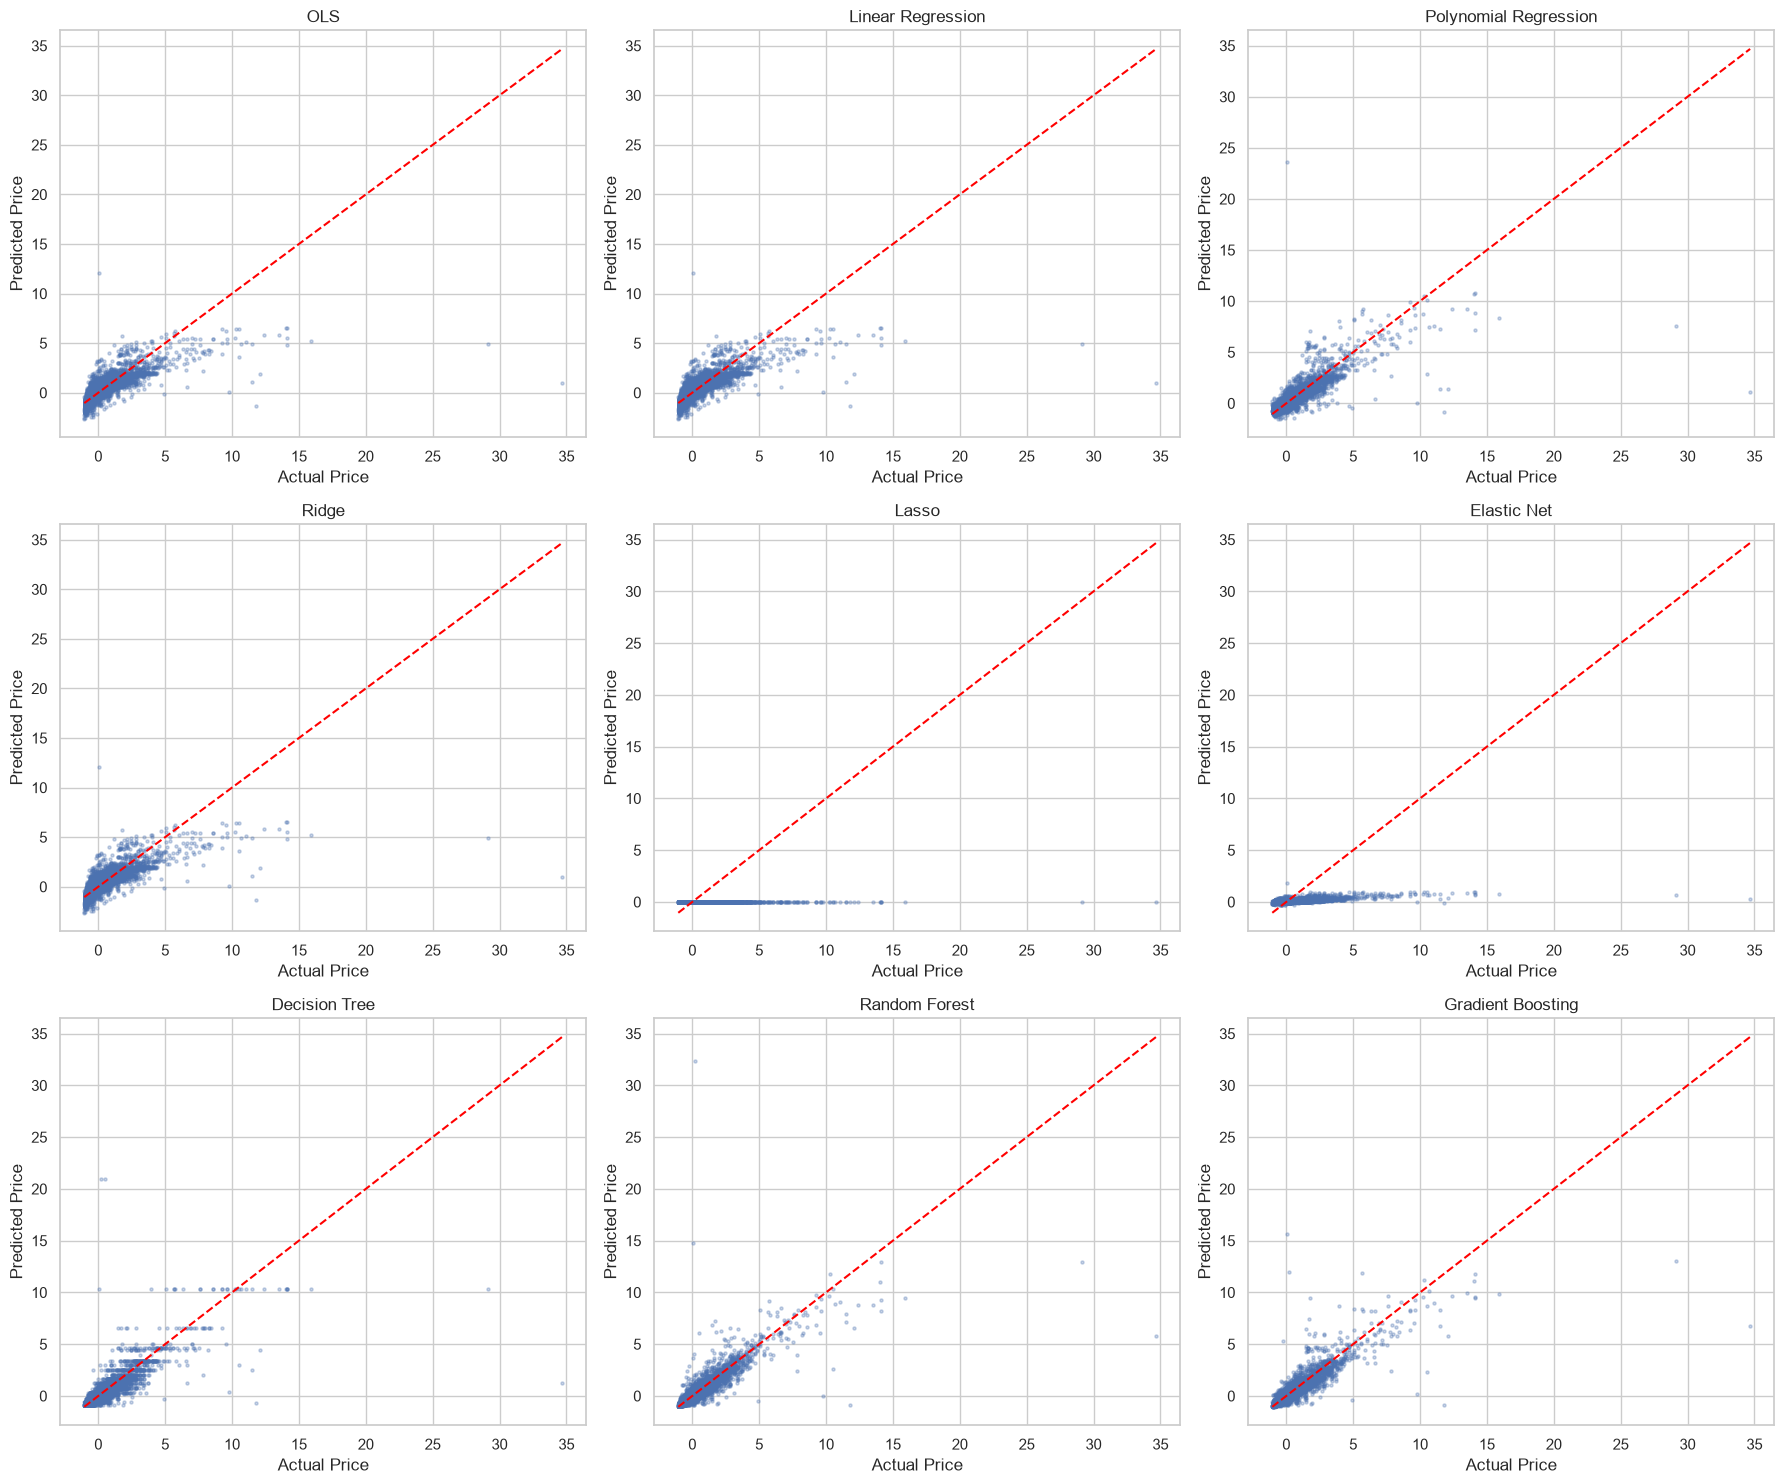

In [68]:
fig, axes = plt.subplots(3, 3, figsize=(18, 15))

for ax, (name, pred) in zip(axes.flatten(), predictions.items()):
    ax.scatter(y_test, pred, s=5, alpha=0.3)
    ax.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        color="red",
        linestyle="--"
    )
    ax.set_title(name)
    ax.set_xlabel("Actual Price")
    ax.set_ylabel("Predicted Price")

plt.tight_layout()
plt.show()

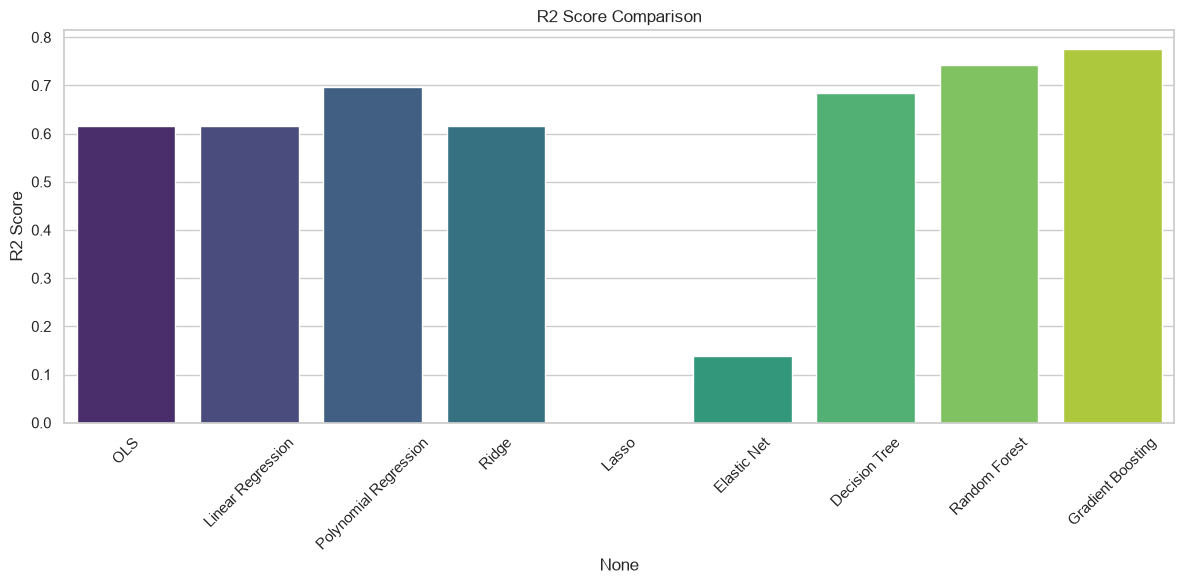

In [70]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=comparison.index,
    y=comparison["R2 Score"],
    hue=comparison.index,
    palette="viridis",
    legend=False
)

plt.xticks(rotation=45)
plt.title("R2 Score Comparison")
plt.tight_layout()
plt.show()

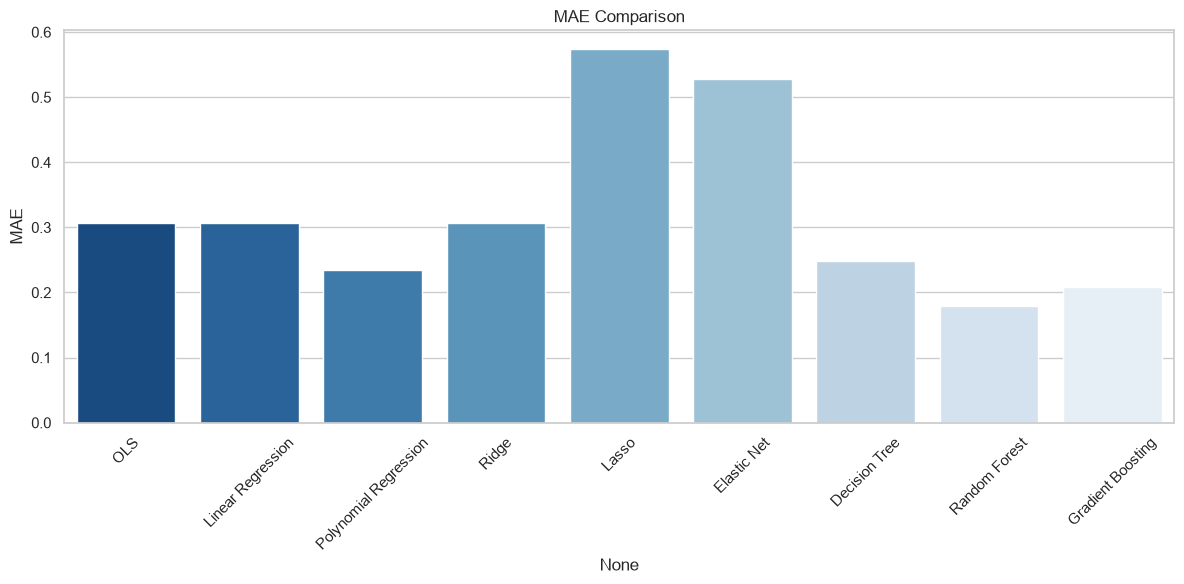

In [71]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=comparison.index,
    y=comparison["MAE"],
    hue=comparison.index,
    palette="Blues_r",
    legend=False
)

plt.xticks(rotation=45)
plt.title("MAE Comparison")
plt.tight_layout()
plt.show()

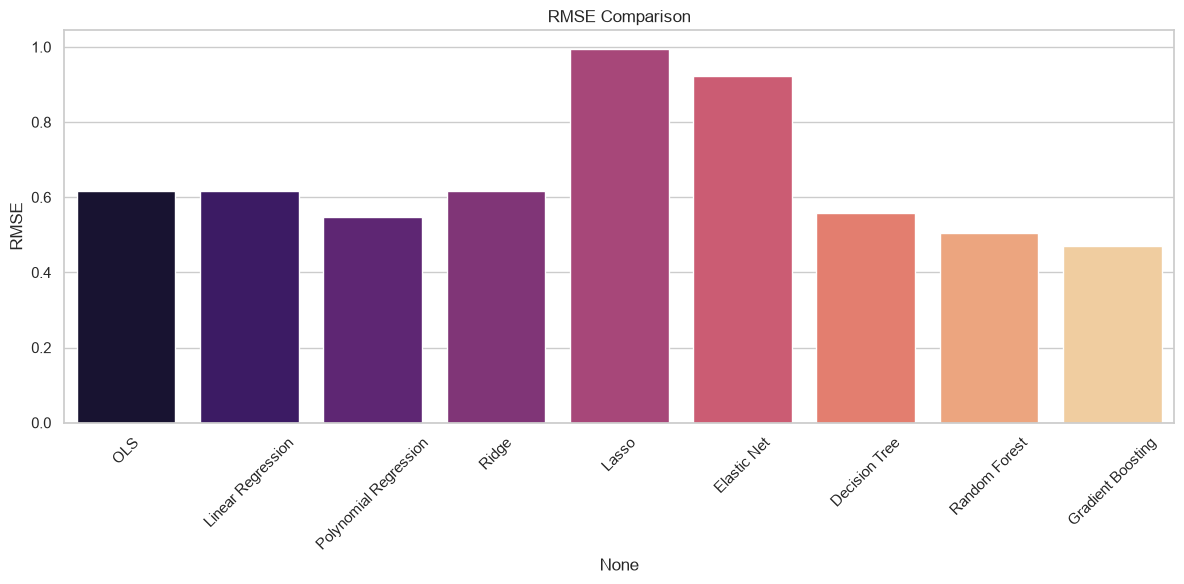

In [72]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=comparison.index,
    y=comparison["RMSE"],
    hue=comparison.index,
    palette="magma",
    legend=False
)

plt.xticks(rotation=45)
plt.title("RMSE Comparison")
plt.tight_layout()
plt.show()

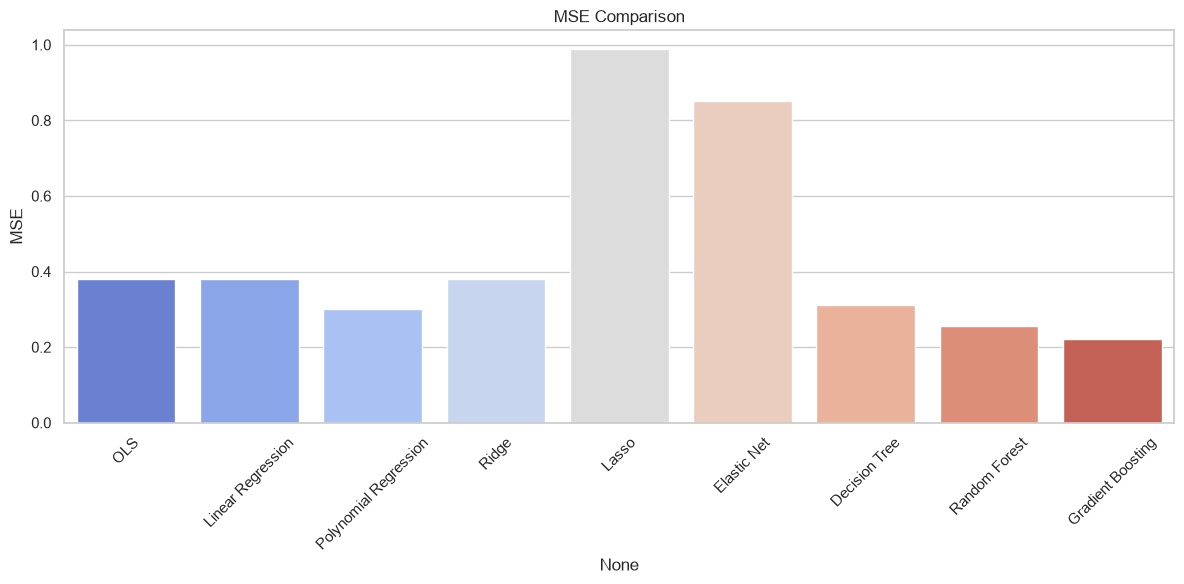

In [73]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=comparison.index,
    y=comparison["MSE"],
    hue=comparison.index,
    palette="coolwarm",
    legend=False
)

plt.xticks(rotation=45)
plt.title("MSE Comparison")
plt.tight_layout()
plt.show()

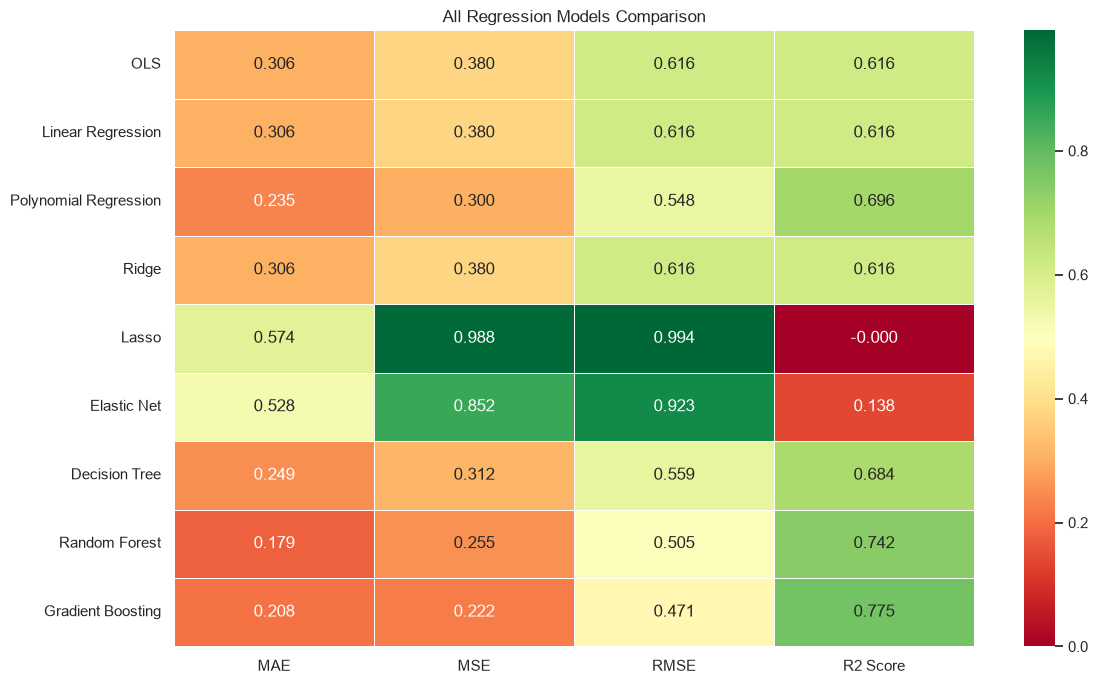

In [74]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    comparison,
    annot=True,
    fmt=".3f",
    cmap="RdYlGn",
    linewidths=0.5
)

plt.title("All Regression Models Comparison")
plt.tight_layout()
plt.show()

In [75]:
comparison = comparison.sort_values(
    by="R2 Score",
    ascending=False
)

display(comparison)

,MAE,MSE,RMSE,R2 Score
Gradient Boosting,0.21,0.22,0.47,0.78
Random Forest,0.18,0.26,0.51,0.74
Polynomial Regression,0.23,0.30,0.55,0.70
Decision Tree,0.25,0.31,0.56,0.68
Ridge,0.31,0.38,0.62,0.62
OLS,0.31,0.38,0.62,0.62
Linear Regression,0.31,0.38,0.62,0.62
Elastic Net,0.53,0.85,0.92,0.14
Lasso,0.57,0.99,0.99,-0.00
